In [26]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Imports

In [27]:
import pandas as pd
import numpy as np
import io
import networkx as nx
from math import prod

from io import StringIO
from itertools import product, combinations, permutations
from scipy.stats import pearsonr

from matplotlib import pyplot as plt
from matplotlib import rcParams
import seaborn as sns

import logging

In [28]:
logger = logging.getLogger()
#logger.setLevel(logging.DEBUG)
logger.setLevel(logging.INFO)

In [29]:
from utils.utils import visualise_test

In [30]:
from utils.input import read_subsystems

In [31]:
from analysis.community import Community, Hegemon, analyse_local_community, detect_local_communities
from analysis.network_analysis import get_networks, countCentrality, get_network_from_year_df, plotWithPyvis
from analysis.dataset_testing import pretest_dataset, test_triple_df

from data_handling import sipri, jme, interventions, deployments, fdi, trade, hitech, energy, refugee
from data_handling import migrant, tourism, humanun, visits, peacekeep, oda, students

from analysis.hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from utils.utils import get_all_countries, get_empty_country_df, get_system_members, get_percent_df, test_df
from utils.utils import test_sphere, row_geometric_mean
from utils.countryconverter import convert_country_df
from utils.df_processing import merge_sphere, normalize, remove_self_loops, show_top, to_mean

### Constant variables

In [32]:
YEAR_START=1985
YEAR_END=2022
SUBSYSTEM_WEIGHTS = {  # BY IHES 2022students-dos
    'human' : 1.79 / (1.79+2.4+3.2),
    'economy' : 2.4 / (1.79+2.4+3.2),
    'security' : 3.2 / (1.79+2.4+3.2)#,
#    'climate' : 2.64
}
#ECONOMY_WEIGHTS = {
#    'fdi':0.5,
#    'trade':0.5,
#    'hitech':0.2,
#    'energy':0.3
#}
ECONOMY_WEIGHTS = {  # IHES Wave V
    'fdi':3.27,
    'trade':2.7,
    'hitech':3.6,
    'energy':3.6
}
HUMAN_WEIGHTS = {
    'migrant':0.16,
    'refugee':0.17,
    'humanun':0.155,
    'oda':0.198,
    'students':0.14
}
SECURITY_WEIGHTS = {
    'interventions':0.13,
    'sipri':0.12,
    'deployments':0.145,
    'jme':0.1  #incorrect
}

SUBSYSTEMS = ['economy', 'security', 'human']
SUBSYSTEMS_RU = {
    'economy':'экономическая',
    'security':'безопасность',
    'human':'гуманитарная',
    'OVERALL':'мировая политика в совокупности'
}
PLOT_GREY = False
RUSSIFY_VISUALS = True
rolling_window = 5
isDigraph = True

RANKMIN=10  # Минимальный ранг в любой год, чтобы отражать страну в графике
MAXRANK=50  # Максимальный ранг, чтобы отражать ранг страны в конкретный год в графике
SPHERE='security'  #  Default sphere

### Functions

In [33]:
def analyse_system(processed_dfs, year_start, year_end, centrality_type='pagerank', print_trace=False, count_abs=False):
    # Analyzing centrality in the international system
    subsystems = {}
    centrality_data = []# sm_dyads.drop('alter', axis=1).drop_duplicates().set_index(['ego','year'])
    for subsystem in processed_dfs:
        logging.info(f"Analysing {subsystem}")
        df = processed_dfs[subsystem]
        
        df = df.reset_index()
        df['year'] = df['year'].astype(int)
        df = df.set_index(['year', 'alter', 'ego'], drop=True)
        countries_all = get_all_countries(processed_df=df.reset_index(), ego_column = 'ego', alter_column = 'alter')  # getting set of all countries
        networks = get_networks(df, countries_all, year_start=YEAR_START, 
                                year_end=YEAR_END, isDigraph=isDigraph,
                                count_abs=count_abs, print_trace=print_trace
                               )  # getting networks
        
        subsystems[subsystem] = {'data': df, 'networks':networks}
        for y in range(year_start, year_end+1):
            df_y = df.reset_index()
            df_y = df_y[df_y['year']==y]
            countries_all = set(df_y['ego']) or set(df_y['alter'])
            #countries_all = get_all_countries(processed_df=df_y.reset_index(), ego_column = 'ego', alter_column = 'alter')  # getting set of all countries
            if print_trace:
                print(y, subsystem)
            if type(centrality_type) == str:
                centrality = countCentrality(networks[y], country_list = countries_all, centrality_type=centrality_type, prefix='')
            elif type(centrality_type) == dict:  # Dict with subsystem names and centrality types
                centrality = countCentrality(networks[y], country_list = countries_all, centrality_type=centrality_type[subsystem], prefix='')
            else:
                raise TypeError(f"Expected centrality_type to be str or dict, got {type(centrality_type)} instead")
            #return centrality[0], centrality[1]
            centrality = centrality.sort_values(f'status')
            centrality['year'] = y
            centrality['subsystem'] = subsystem
            centrality_data += centrality,
    centrality_result = pd.concat(centrality_data)
    return centrality_result.reset_index().rename({'index':'ego'}, axis=1), subsystems

def combine_spheres(analysis): # Combining spheres via centrality
    
    status_combined = analysis.groupby(['ego', 'year']).sum()
    status_combined['weighted_centrality'] = status_combined['weighted_centrality'].astype(float)
    status_combined['rank_combined'] = status_combined['weighted_centrality'].groupby(['year']).rank(ascending=False, method='min')
    #status_combined['weighted_centrality'].rank(ascending=False, method='min')
    return status_combined

def visualize_sphere(analysis, rankmin=RANKMIN, maxrank=MAXRANK, sphere=SPHERE, plot_grey=PLOT_GREY, russify=RUSSIFY_VISUALS):
    # Подготовка данных
    data = analysis[analysis['subsystem']==sphere]
    if russify:
        data = convert_country_df(data, data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
        sphere_name = SUBSYSTEMS_RU[sphere]
    else:
        sphere_name = sphere
        
    #print(data)
    egos_top = data[data['rank']<=rankmin]['ego'].unique()
    data = data[data['ego'].isin(egos_top)]
    data = data[data['rank']<=maxrank]
    #pivot_data = data.pivot_table(index='ego', columns='year', values='rank').sort_values(YEAR_END, ascending=True)
    pivot_data = data.pivot_table(index='ego', columns='year', values='rank').sort_values(YEAR_END, ascending=True)
    plt.figure(figsize=(15, 6.5))
    if plot_grey:
        cmap = plt.get_cmap('Greys', 20)
    else:
        cmap='YlOrRd'
    sns.heatmap(pivot_data, annot=True, cmap=cmap, linewidths=1.8)
    if russify: 
        plt.xlabel('год')
        plt.ylabel('альтер')
    plt.title(f'Тепловая карта по рангу стран ({sphere_name})')
    plt.text(0.5, -0.17,  
             f"*Примечание: пустые ячейки означают ранг >{maxrank} или отсутствие данных",
             ha='left', 
             va='center', 
             transform=plt.gca().transAxes,
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    plt.savefig(f'../output/{sphere}_ranks{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
    plt.show()

def visualize_overall(status_combined, plot_grey = PLOT_GREY, rankmin=RANKMIN, rankmax=MAXRANK, russify=RUSSIFY_VISUALS):

    SPHERE ='OVERALL'

    data = status_combined.reset_index()
    if russify:
        data = convert_country_df(data, data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
        SPHERE = SUBSYSTEMS_RU[SPHERE]
    egos_top = data[data['rank_combined']<=rankmin]['ego'].unique()
    data = data[data['ego'].isin(egos_top)]
    data = data[data['rank_combined']<=rankmax]
    
    pivot_data = data.pivot_table(index='ego', columns='year', values='rank_combined').sort_values(YEAR_END, ascending=True)
    
    plt.figure(figsize=(15, 6.5))
    if plot_grey:
        cmap = plt.get_cmap('Greys', 20)
    else:
        cmap='YlOrRd'
    sns.heatmap(pivot_data, annot=True, cmap=cmap, linewidths=1.8)
    plt.title(f'Тепловая карта по рангу стран ({SPHERE})')
    plt.xlim=(1992,2023)
    if russify: 
        plt.xlabel('год')
        plt.ylabel('альтер')
    plt.text(0.5, -0.17,  
             f"*Примечание: пустые ячейки означают ранг >{rankmax} или отсутствие данных",
             ha='left', 
             va='center', 
             transform=plt.gca().transAxes,
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    plt.savefig(f'../output/{SPHERE}_ranks{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
    plt.show()

## Data preprocessing

##### Arms Trade (SIPRI)

INFO:root:Loaded SIPRI Arms Transfer Data
INFO:root:Preprocessing SIPRI Arms Transfer Data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Western Sahara, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier South Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier North Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Northern Cyprus, replacing with None
  if warning: warnings.warn(f

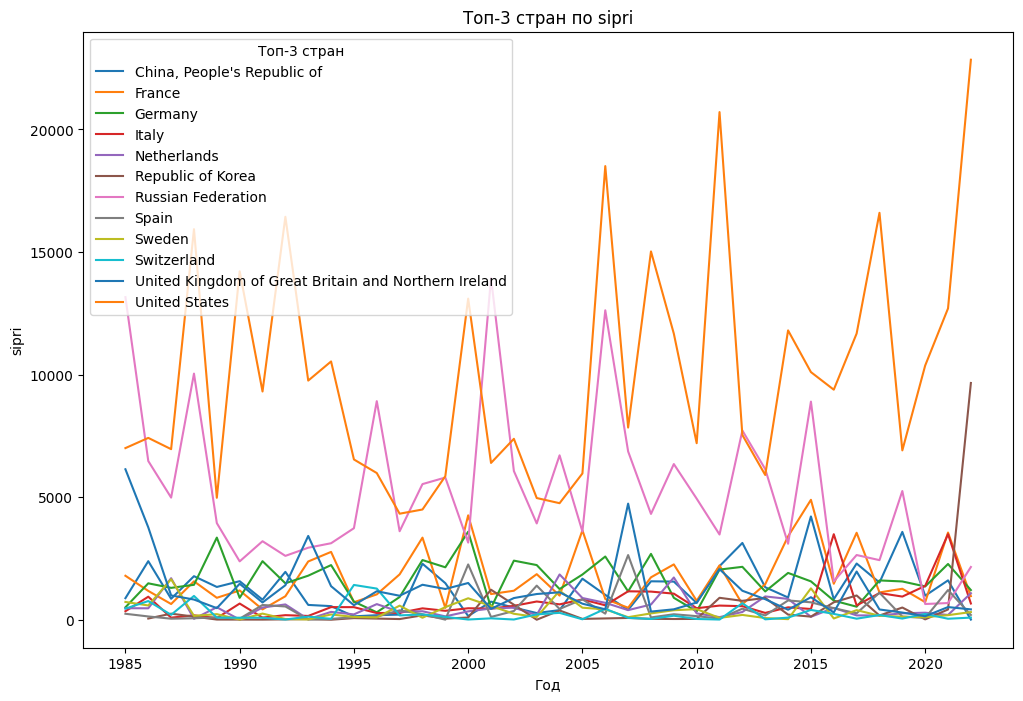

In [34]:
sipri_df = sipri.load_sipri()
sipri_df, sipri_processed_df = sipri.preprocess_sipri(sipri_df, year_start=1985, rolling_window=5)
sipri_df.to_csv("../data/basic_preprocessed/arms.csv")
sipri_processed_df.to_csv("../data/preprocessed/arms.csv")

In [35]:
sipri_df = pd.read_csv("../data/basic_preprocessed/arms.csv").drop('Unnamed: 0', axis=1)
sipri_processed_df = pd.read_csv("../data/preprocessed/arms.csv").set_index(['ego', 'alter', 'year'])

In [36]:
# Проблема: Польша продавала оружие США и СССР в один год
# Проблема: высокий показатель у Непала из-за миротворческих операций ООН - убрали операцию

##### Interventions (Correlates of military interventions)

In [37]:
interventions_df = interventions.load_interventions()
interventions_df, interventions_processed_df = interventions.preprocess_interventions(interventions_df, year_start=1985, neighbourhood_type=None, rolling_window=5)
interventions_df.to_csv("../data/basic_preprocessed/interventions.csv")
interventions_processed_df.to_csv("../data/preprocessed/interventions.csv")

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 49, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 429, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 619, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 678, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryc

230 Spain
432 Mali
812 Lao People's Democratic Republic
651 Egypt
666 Israel
820 Malaysia
616 Tunisia
49 None
540 Angola
429 None
355 Bulgaria
551 Zambia
619 None
678 None
517 Rwanda
1016 None
475 Nigeria
93 Nicaragua
115 Suriname
811 Cambodia
553 Malawi
620 Libya
380 Sweden
40 Cuba
3602 None
732 Republic of Korea
20 Canada
775 Myanmar
483 Chad
770 Pakistan
367 Latvia
3482 None
653 None
740 Japan
235 Portugal
390 Denmark
372 Georgia
679 Yemen
3850 None
731 Democratic People's Republic of Korea
100 Colombia
433 Senegal
315 Czechoslovakia
771 Bangladesh
830 Singapore
255 Germany
696 United Arab Emirates
900 Australia
345 Serbia
3903 None
640 Türkiye
92 El Salvador
343 Republic of North Macedonia
2460 None
265 German Democratic Republic
817 None
200 United Kingdom of Great Britain and Northern Ireland
695 None
850 Indonesia
3300 None
710 China, People's Republic of
663 Jordan
316 Czechia
955 Tonga
670 Saudi Arabia
510 United Republic of Tanzania
101 Venezuela (Bolivarian Republic of)
660 

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 678, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 755, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 511, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 601, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/country

230 Spain
432 Mali
812 Lao People's Democratic Republic
651 Egypt
666 Israel
820 Malaysia
616 Tunisia
450 Liberia
935 Vanuatu
540 Angola
355 Bulgaria
551 Zambia
205 Ireland
517 Rwanda
678 None
755 None
93 Nicaragua
940 Solomon Islands
475 Nigeria
811 Cambodia
346 Bosnia and Herzegovina
780 Sri Lanka
620 Libya
511 None
40 Cuba
732 Republic of Korea
55 Grenada
570 Lesotho
775 Myanmar
483 Chad
770 Pakistan
740 Japan
235 Portugal
372 Georgia
679 Yemen
601 None
731 Democratic People's Republic of Korea
100 Colombia
433 Senegal
781 Maldives
315 Czechoslovakia
771 Bangladesh
255 Germany
31 Bahamas
338 Malta
790 Nepal
345 Serbia
640 Türkiye
92 El Salvador
343 Republic of North Macedonia
265 German Democratic Republic
437 Côte d'Ivoire
110 Guyana
817 None
200 United Kingdom of Great Britain and Northern Ireland
395 Iceland
695 None
850 Indonesia
860 Timor-Leste
753 None
710 China, People's Republic of
663 Jordan
41 Haiti
411 Equatorial Guinea
670 Saudi Arabia
754 None
510 United Republic of Tan

NameError: name 'PATH_TO_KEY_DF' is not defined

In [ ]:
interventions_df = pd.read_csv("../data/basic_preprocessed/interventions.csv").drop('Unnamed: 0', axis=1)
interventions_processed_df = pd.read_csv("../data/preprocessed/interventions.csv").set_index(['ego', 'alter', 'year'])

##### Peacekeeping

#####  Joint military exercises

In [ ]:
jme_df = pd.read_csv("../data/basic_preprocessed/jme.csv").drop('Unnamed: 0', axis=1)
jme_processed_df = pd.read_csv("../data/preprocessed/jme.csv").set_index(['ego', 'alter', 'year'])

##### Military deployments

In [ ]:
# from https://github.com/EmilStasevski/Military-Deployment/tree/main
# based on IISS Military Balance

In [ ]:
deployments_df = deployments.load_deployments(filter_un=True)
deployments_df, deployments_processed_df = deployments.preprocess_deployments(deployments_df, year_start=YEAR_START, logarithmic=True)
deployments_df.to_csv("../data/basic_preprocessed/deployments.csv")
deployments_processed_df.to_csv("../data/preprocessed/deployments.csv")

In [ ]:
deployments_df = pd.read_csv("../data/basic_preprocessed/deployments.csv").drop('Unnamed: 0', axis=1)
deployments_processed_df = pd.read_csv("../data/preprocessed/deployments.csv").set_index(['ego', 'alter', 'year'])

##### Merging

In [ ]:
d_ = interventions_processed_df.reset_index()
d_['value'] = d_['value'].replace(0, None)
d_ = d_.dropna()
d_=d_.groupby(['ego','year']).sum().reset_index()
d_[d_['ego']=='Sweden']

In [ ]:
d_ = sipri_processed_df.reset_index()
d_['value'] = d_['value'].replace(0, None)
d_ = d_.dropna()
d_=d_.groupby(['ego','year']).sum().reset_index()
d_[d_['ego']=='Sweden']

In [ ]:
security_dfs = {
    'interventions':interventions_processed_df,
    'sipri':sipri_processed_df,
    'deployments':deployments_processed_df,          
    #'jme':jme_processed_df
}
security_triple = merge_sphere(security_dfs, SECURITY_WEIGHTS, test=True, label='security')

### Economy

#### Hi-tech trade

INFO:root:reading 2005.csv


['2005.csv', '2019.csv', '1996.csv', '2021.csv', '1989.csv', '2006.csv', '2022.csv', '2000.csv', '1990.csv', '2002.csv', '1992.csv', '2020.csv', '1997.csv', '2004.csv', '1993.csv', '2001.csv', '2018.csv', '1991.csv', '1998.csv', '1999.csv', '1995.csv', '2003.csv', '1994.csv', '2007.csv', '2008.csv', '2009.csv', '2017.csv', '2010.csv', '2011.csv', '2015.csv', '2016.csv', '2012.csv', '2014.csv', '2013.csv', '1988.csv', '1987.csv', '1986.csv', '1985.csv', '1985_1995_USSR_RUssia_mirror.csv', '2013_2024_SaudiArabia_Venezuela_Libya_mirror.csv', '2001_2012_SaudiArabia_Venezuela_Libya_mirror.csv']


INFO:root:reading 2019.csv
INFO:root:reading 1996.csv
INFO:root:reading 2021.csv
INFO:root:reading 1989.csv
INFO:root:reading 2006.csv
INFO:root:reading 2022.csv
INFO:root:reading 2000.csv
INFO:root:reading 1990.csv
INFO:root:reading 2002.csv
INFO:root:reading 1992.csv
INFO:root:reading 2020.csv
INFO:root:reading 1997.csv
INFO:root:reading 2004.csv
INFO:root:reading 1993.csv
INFO:root:reading 2001.csv
INFO:root:reading 2018.csv
INFO:root:reading 1991.csv
INFO:root:reading 1998.csv
/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/hitech.py:39: DtypeWarning: Columns (0: qtyUnitAbbr) have mixed types. Specify dtype option on import or set low_memory=False.
  hitech_data_piece = pd.read_csv(hitech_PATH+file, encoding='latin-1', index_col=False)#, index_col=None, header=None, quoting=csv.QUOTE_ALL)
INFO:root:reading 1999.csv
INFO:root:reading 1995.csv
INFO:root:reading 2003.csv
INFO:root:reading 1994.csv
INFO:root:reading 2007.csv
/home/alex-server/Sync/Работа/Code/phd_thesi

TKL None
PLW Palau
ITA Italy
URY Uruguay
GRL None
VUT Vanuatu
KHM Cambodia
UMI None
SXM None
AFG Afghanistan
NZL New Zealand
ZWE Zimbabwe
MSR None
GRC Greece
GHA Ghana
SYC Seychelles
LTU Lithuania
GTM Guatemala
OMN Oman
BEL Belgium
NER Niger
HUN Hungary
PNG Papua New Guinea
KEN Kenya
MAR Morocco
FIN Finland
MOZ Mozambique
CPV Cabo Verde
YMD None
NCL None
MMR Myanmar
PCI None
MNG Mongolia
AGO Angola
NTZ None
FJI Fiji
AUT Austria
GBR United Kingdom of Great Britain and Northern Ireland
ATA None
AIA None
HKG None
YEM Yemen
SDN Sudan
RWA Rwanda
NIU None
TCD Chad
KOR Republic of Korea
IOT None
O19 None
COM Comoros
CCK None
CYM None
SWE Sweden
EST Estonia
NIC Nicaragua
GMB Gambia
ALB Albania
VEN Venezuela (Bolivarian Republic of)
SGS None
SMR San Marino
HTI Haiti
WLF None
DNK Denmark
TUR Türkiye
ROU Romania
SUR Suriname
BHR Bahrain
IDN Indonesia
MLI Mali
KIR Kiribati
PSE State of Palestine
RUS Russian Federation
POL Poland
IRQ Iraq
TUN Tunisia
S19 None
USA United States
BTN Bhutan
KWT Kuwait

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier GRL, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier MSR, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier NCL, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier AIA, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/country

PLW Palau
GRL None
ITA Italy
URY Uruguay
VUT Vanuatu
KHM Cambodia
AFG Afghanistan
NZL New Zealand
ZWE Zimbabwe
MSR None
GRC Greece
GHA Ghana
SYC Seychelles
LTU Lithuania
GTM Guatemala
OMN Oman
BEL Belgium
NER Niger
PNG Papua New Guinea
HUN Hungary
KEN Kenya
MAR Morocco
FIN Finland
MOZ Mozambique
CPV Cabo Verde
NCL None
MMR Myanmar
MNG Mongolia
AGO Angola
FJI Fiji
AUT Austria
GBR United Kingdom of Great Britain and Northern Ireland
AIA None
HKG None
YEM Yemen
SDN Sudan
RWA Rwanda
KOR Republic of Korea
COM Comoros
EST Estonia
SWE Sweden
CYM None
NIC Nicaragua
GMB Gambia
ALB Albania
VEN Venezuela (Bolivarian Republic of)
HTI Haiti
DNK Denmark
TUR Türkiye
ROU Romania
MLI Mali
BHR Bahrain
IDN Indonesia
SUR Suriname
PSE State of Palestine
KIR Kiribati
RUS Russian Federation
POL Poland
TUN Tunisia
USA United States
S19 None
BTN Bhutan
KWT Kuwait
MDG Madagascar
TON Tonga
DJI Djibouti
BHS Bahamas
EGY Egypt
BDI Burundi
PRT Portugal
MAC None
NOR Norway
AUS Australia
PHL Philippines
ANT None
CSK N

INFO:root:Testing initiated
INFO:root:Missing 14(182/196 = (0.9285714285714286)) egos, 3(193/196 = 0.9846938775510204) alters, 0 years
INFO:root:Missing egos: {'San Marino', 'Iraq', "Democratic People's Republic of Korea", 'Marshall Islands', 'Liechtenstein', 'Monaco', 'Somalia', 'Chad', 'Czechoslovakia', 'South Sudan', 'Micronesia (Federated States of)', 'Equatorial Guinea', 'Nauru', 'German Democratic Republic'}
INFO:root:Missing great egos: set()
INFO:root:Missing alters: {'Czechoslovakia', 'Liechtenstein', 'German Democratic Republic'}
INFO:root:Missing great alters: set()
INFO:root:Missing years: set()
INFO:root:1316492 - 383042 = 933450 lines missing (0.2909565724668285)
INFO:root:
INFO:root:                                   0
Source name                   hitech
Missing egos                      14
Missing great egos                 0
Missing alters                     3
Missing great alters               0
Missing years                      0
Missing yearly dyads           272

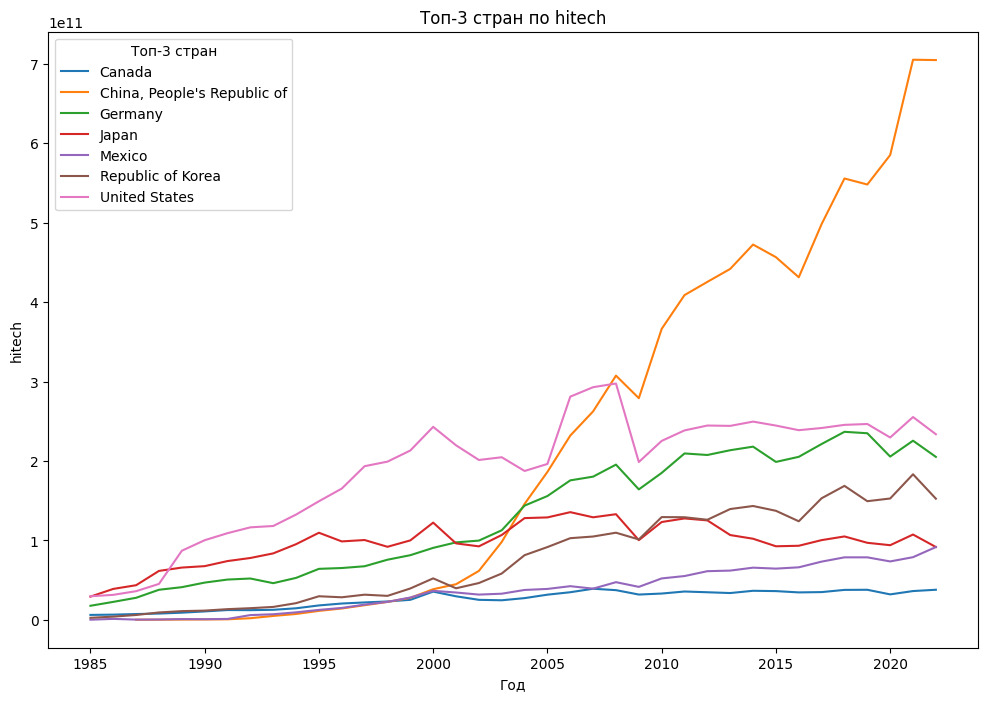

In [39]:
hitech_df = hitech.load_hitech()
hitech_df, hitech_processed_df = hitech.preprocess_hitech(hitech_df, year_start=YEAR_START, rolling_window=5)
hitech_df.to_csv("../data/basic_preprocessed/hitech.csv")
hitech_processed_df.to_csv("../data/preprocessed/hitech.csv")

In [40]:
hitech_df = pd.read_csv("../data/basic_preprocessed/hitech.csv")
hitech_processed_df = pd.read_csv("../data/preprocessed/hitech.csv").set_index(['ego', 'alter', 'year'])

/tmp/ipykernel_1833307/2705072775.py:1: DtypeWarning: Columns (0: altQtyUnitAbbr) have mixed types. Specify dtype option on import or set low_memory=False.
  hitech_df = pd.read_csv("../data/basic_preprocessed/hitech.csv")


#### Merging

INFO:root:saving figure


{'hitech':                                                  ego          value
0                                           Malaysia   41775.258766
1                                        Netherlands   51118.853149
2  United Kingdom of Great Britain and Northern I...   61063.447852
3                                          Singapore   65367.915312
4                                             France   67838.691101
5                                  Republic of Korea   73721.810392
6                                              Japan   99465.383234
7                                            Germany  127332.707456
8                                      United States  189481.696997
9                        China, People's Republic of  196971.377604, 'overall_sphere':                                                  ego          value
0                                           Malaysia  150390.931557
1                                        Netherlands  184027.871337
2  United Kingdom 

INFO:root:saving figure


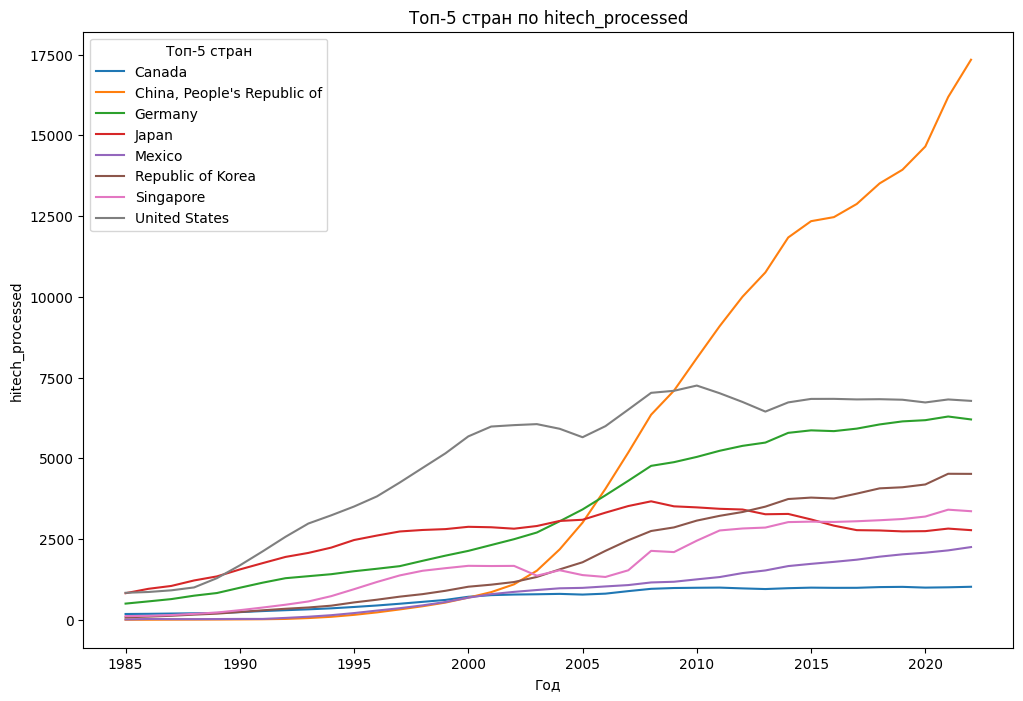

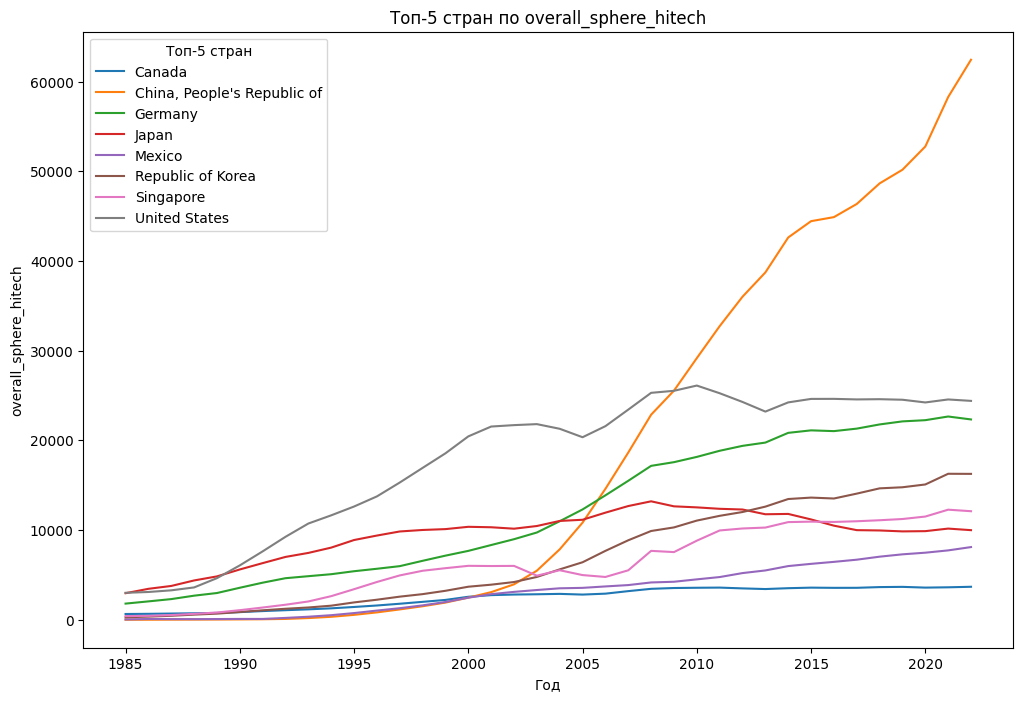

In [41]:
economy_dfs = {
    'hitech':hitech_processed_df,
}
hitech_triple = merge_sphere(economy_dfs, ECONOMY_WEIGHTS, test=True, label='hitech')

In [ ]:
oda_df = pd.read_csv("../data/basic_preprocessed/oda.csv")
oda_processed_df = pd.read_csv("../data/preprocessed/oda.csv").set_index(['ego', 'alter', 'year'])

In [ ]:
humanun_df = humanun.load_humanun()
humanun_df, humanun_processed_df = humanun.preprocess_humanun(humanun_df, year_start=YEAR_START, year_end=YEAR_END, rolling_window=5, normalize=True, extrapolate=True)
humanun_df.to_csv("../data/basic_preprocessed/humanun.csv")
humanun_processed_df.to_csv("../data/preprocessed/humanun.csv")

In [ ]:
humanun_df = pd.read_csv("../data/basic_preprocessed/humanun.csv")
humanun_processed_df = pd.read_csv("../data/preprocessed/humanun.csv").set_index(['ego', 'alter', 'year'])

In [ ]:
# MIGRANT - почему штаты не первые? - из-за лог шкалы
# REFUGEE - почему Иран Турция не первые? - из-за лог шкалы

In [ ]:
test_sphere(human_dfs, years = [2022])

In [ ]:
human_dfs = {
    'migrant':migrant_processed_df,
    'refugee':refugee_processed_df,
    'humanun':humanun_processed_df,
    'oda':oda_processed_df,
    'students' :students_processed_df
}
human_triple = merge_sphere(human_dfs, HUMAN_WEIGHTS, test=True, label='human')

#### Diplomatic visits

In [ ]:
visits_df = visits.load_visits()
visits_df, visits_processed_df = visits.preprocess_visits(visits_df, year_start=YEAR_START, year_end=YEAR_END, rolling_window=5, normalize=True)
visits_df.to_csv("../data/basic_preprocessed/visits.csv")
visits_processed_df.to_csv("../data/preprocessed/visits.csv")

In [ ]:
visits_df = pd.read_csv("../data/basic_preprocessed/visits.csv")#.drop('Unnamed: 0', axis=1)
visits_processed_df = pd.read_csv("../data/preprocessed/visits.csv").set_index(['ego', 'alter', 'year'])#.drop('Unnamed: 0', axis=1)

# Network Analysis

## Constructing network

In [ ]:
# Почему для Белорусии и России security нет

In [ ]:
mask = (economy_triple.reset_index()['ego']=='Czechia')&(economy_triple.reset_index()['year']==2022)
economy_triple.reset_index().loc[mask].sort_values('value').sum()

In [ ]:
economy_triple.drop('index', axis=1, inplace=True)

##### Strong connectivity

In [ ]:
# need to compute subsystems first
for sphere in subsystems:
    for year in range(YEAR_START, YEAR_END+1):
        g = subsystems[sphere]['networks'][year] 
        print(sphere, year, nx.is_strongly_connected(g))

#### Main

In [42]:
## Translation

In [43]:
if RUSSIFY_VISUALS:
    df = hitech_processed_df.reset_index().drop_duplicates(subset='ego').copy()
    df['ego_en'] = df['ego']
    df = convert_country_df(df.reset_index(), data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
    translation_dict = df.set_index('ego_en', drop=True)[['ego']].to_dict()['ego']

In [44]:
if RUSSIFY_VISUALS:
    hitech_triple=hitech_triple.reset_index().replace(translation_dict).set_index(['year', 'alter', 'ego'])

In [45]:
# DATA ANSLYSIS
processed_dfs = {
    'hitech' : hitech_triple.fillna(0)
}
centrality_types = {
    'hitech' : 'reverse_pagerank',#'reverse_pagerank',
}
for sphere in processed_dfs:
    if centrality_types[sphere] == 'betweenness':
        processed_dfs[sphere]['value'] = (processed_dfs[sphere]['value']*100).astype(int) #  for betweenness centrality

analysis, subsystems = analyse_system(processed_dfs, print_trace=False,
                                      year_start=YEAR_START, year_end=YEAR_END, 
                                      centrality_type=centrality_types, count_abs=False
                                      )
#analysis, subsystems = analyse_system(processed_dfs, print_trace=True,
#                                      year_start=YEAR_START, year_end=YEAR_END, 
#                                      centrality_type='reverse_pagerank', count_abs=False)

# node, G = analyse_system(processed_dfs, year_start=YEAR_START, year_end=YEAR_END, centrality_type='out-degree-weighted')
# analysis, subsystems = analyse_system(processed_dfs, year_start=YEAR_START, year_end=YEAR_END, centrality_type='katz', count_abs=True)
# katz - не подходит для полных сетей
# eigenvector - если мои друзья влиятельны, то и я буду более влиятельным. Не работает. Так как связи с изолированными тоже дает влияние
# betweenness centrality - для роли посредничества.
# random_walk_betweenness - не учитывает направление связей
# communicability - не учитывает веса связей
# trophic levels - не учитывает веса связей
# closeness vitality - слишком нестабильные результаты, графы не являются сильно связанными

logging.info(f"Веса: {SUBSYSTEM_WEIGHTS}")
analysis_weighted = analysis.fillna(0).groupby(['ego', 'year']).centrality.agg(lambda x: row_geometric_mean(
    row=x, subsystem_weights=SUBSYSTEM_WEIGHTS, print_rows=False))
analysis = analysis.set_index(['ego', 'year'])
analysis['weighted_centrality'] = analysis_weighted
analysis = analysis.reset_index()

status_combined = combine_spheres(analysis)
analysis=analysis.reset_index(drop=True)

INFO:root:Analysing hitech
INFO:root:there are 196 unique countries, 196 - ego, 196 - alter
INFO:root:Getting global networks for 1985 - 2022


done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


INFO:root:Done getting networks


done
done
done
done


INFO:root:Веса: {'human': 0.2422192151556157, 'economy': 0.32476319350473615, 'security': 0.43301759133964823}


#### Saving

In [54]:
analysis.to_csv('../data/analysis_hitech.csv')
analysis.to_excel('../data/analysis_hitech.xlsx')
status_combined.to_csv('../data/status_combined_hitech.csv')

#for subsystem, y in product(SUBSYSTEMS, range(YEAR_START, YEAR_END+1)):
#    nx.write_weighted_edgelist(subsystems[subsystem]['networks'][y], f'../data/networks/n_{subsystem}_{y}.nx', comments='#', delimiter='|', encoding='utf-8')
#    nx.write_graphml_lxml(subsystems[subsystem]['networks'][y], f'../data/networks/graphml/n_{subsystem}_{y}.lxml')
#for subsystem in SUBSYSTEMS:
#    subsystems[subsystem]['data'].to_csv(f'../data/preprocessed/subsystem_level/df_{subsystem}_{y}.csv')

In [9]:
analysis=pd.read_csv('../data/analysis.csv', index_col='Unnamed: 0')
status_combined=pd.read_csv('../data/status_combined.csv')

subsystems=read_subsystems(year_start=1985)

INFO:root:Сканируем папку: /home/alex-server/Sync/Работа/Code/phd_thesis/data/preprocessed/subsystem_level
INFO:root:Содержимое папки (4 элементов):
INFO:root:  - df_economy_2022.csv
INFO:root:  - df_security_2022.csv
INFO:root:  - df_human_2022.csv
INFO:root:  - .ipynb_checkpoints
INFO:root:Добавлена категория: 'economy' из файла df_economy_2022.csv
INFO:root:Добавлена категория: 'security' из файла df_security_2022.csv
INFO:root:Добавлена категория: 'human' из файла df_human_2022.csv
INFO:root:Найдено уникальных категорий: 3
INFO:root:Итоговый список категорий: ['economy', 'human', 'security']
INFO:root:reading subsystems ['economy', 'human', 'security']


In [57]:
# США-Гренада в экономике в 1995? Инвестиции. Сомнительно

#### Средняя сетевая связность (сколько связей в среднем приходится на один узел)

In [ ]:
# very_slow
av_connectivity = dict()
for sphere in subsystems:
    av_connectivity[sphere] = dict()
    for y in range (YEAR_START, YEAR_END+1):
        logging.info(f"Getting av connectivity for {sphere}, {y}")
        av_connectivity[sphere][y] = nx.average_node_connectivity(subsystems[sphere]['networks'][y])

av_connectivity_df = pd.DataFrame(pd.DataFrame(av_connectivity).unstack()).reset_index().rename({'level_0':'sphere', 'level_1':'year', 0:'avg_connectivity'}, axis=1)

In [ ]:
# Save
av_connectivity_df.to_csv(f'../data/networks/av_connectivity/av_connectivity.csv')

In [10]:
# Load
av_connectivity_df = pd.read_csv(f'../data/networks/av_connectivity/av_connectivity.csv', index_col='Unnamed: 0')

In [11]:
av_connectivity_df.groupby('sphere').mean()

,year,avg_connectivity
sphere,,
economy,2003.5,64.141078
human,2003.5,49.586846
security,2003.5,0.378460


DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04])
DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([2.e-03, 3.e-03, 4.e-03, 5.e-03, 6.e-03, 7.e-03, 8.e-03, 9.e-03,
       2.e-02, 3.e-02, 4.e-02, 5.e-02, 6.e-02, 7.e-02, 8.e-02, 9.e-02,
       2.e-01, 3.e-01, 4.e-01, 5.e-01, 6.e-01, 7.e-01, 8.e-01, 9.e-01,
       2.e+00, 3.e+00, 4.e+00, 5.e+00, 6.e+00, 7.e+00, 8.e+00, 9.e+00,
       2.e+01, 3.e+01, 4.e+01, 5.e+01, 6.e+01, 7.e+01, 8.e+01, 9.e+01,
       2.e+02, 3.e+02, 4.e+02, 5.e+02, 6.e+02, 7.e+02, 8.e+02, 9.e+02,
       2.e+03, 3.e+03, 4.e+03, 5.e+03, 6.e+03, 7.e+03, 8.e+03, 9.e+03,
       2.e+04, 3.e+04, 4.e+04, 5.e+04, 6.e+04, 7.e+04, 8.e+04, 9.e+04])
DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.

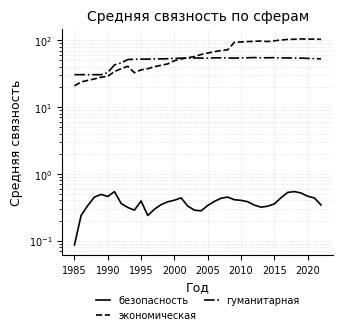

In [1393]:
# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Получаем список сфер в порядке их появления
spheres = av_connectivity_df['sphere'].unique()

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))

for i, sphere in enumerate(spheres):
    # Выбираем данные для конкретной сферы
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere]
    # Сортируем по году (на случай, если данные не упорядочены)
    df_sphere = df_sphere.sort_values('year')
    
    # Стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    ax.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color='black',
        label=SUBSYSTEMS_RU[sphere]
    )

# Логарифмическая шкала по Y для отображения сильно различающихся величин
ax.set_yscale('log')

# Оформление осей
ax.set_title('Средняя связность по сферам')
ax.set_xlabel('Год')
ax.set_ylabel('Средняя связность')
ax.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/avg_connectivity_log{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()

DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([2.e-03, 3.e-03, 4.e-03, 5.e-03, 6.e-03, 7.e-03, 8.e-03, 9.e-03,
       2.e-02, 3.e-02, 4.e-02, 5.e-02, 6.e-02, 7.e-02, 8.e-02, 9.e-02,
       2.e-01, 3.e-01, 4.e-01, 5.e-01, 6.e-01, 7.e-01, 8.e-01, 9.e-01,
       2.e+00, 3.e+00, 4.e+00, 5.e+00, 6.e+00, 7.e+00, 8.e+00, 9.e+00,
       2.e+01, 3.e+01, 4.e+01, 5.e+01, 6.e+01, 7.e+01, 8.e+01, 9.e+01,
       2.e+02, 3.e+02, 4.e+02, 5.e+02, 6.e+02, 7.e+02, 8.e+02, 9.e+02,
       2.e+03, 3.e+03, 4.e+03, 5.e+03, 6.e+03, 7.e+03, 8.e+03, 9.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7

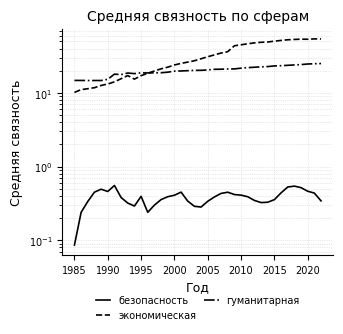

In [1364]:
# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Получаем список сфер в порядке их появления
spheres = av_connectivity_df['sphere'].unique()

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))

for i, sphere in enumerate(spheres):
    # Выбираем данные для конкретной сферы
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere]
    # Сортируем по году (на случай, если данные не упорядочены)
    df_sphere = df_sphere.sort_values('year')
    
    # Стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    ax.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color='black',
        label=SUBSYSTEMS_RU[sphere]
    )

# Логарифмическая шкала по Y для отображения сильно различающихся величин
ax.set_yscale('log')

# Оформление осей
ax.set_title('Средняя связность по сферам')
ax.set_xlabel('Год')
ax.set_ylabel('Средняя связность')
ax.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/avg_connectivity_log{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()

In [1284]:
data = None# analysis[analysis['subsystem']=='economy']
#egos_top = data[data['rank']<=RANKMIN]['ego'].unique()
#data = data[data['ego'].isin(egos_top)]
#data = data[data['rank']<=MAXRANK]

economy


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61f4563010>


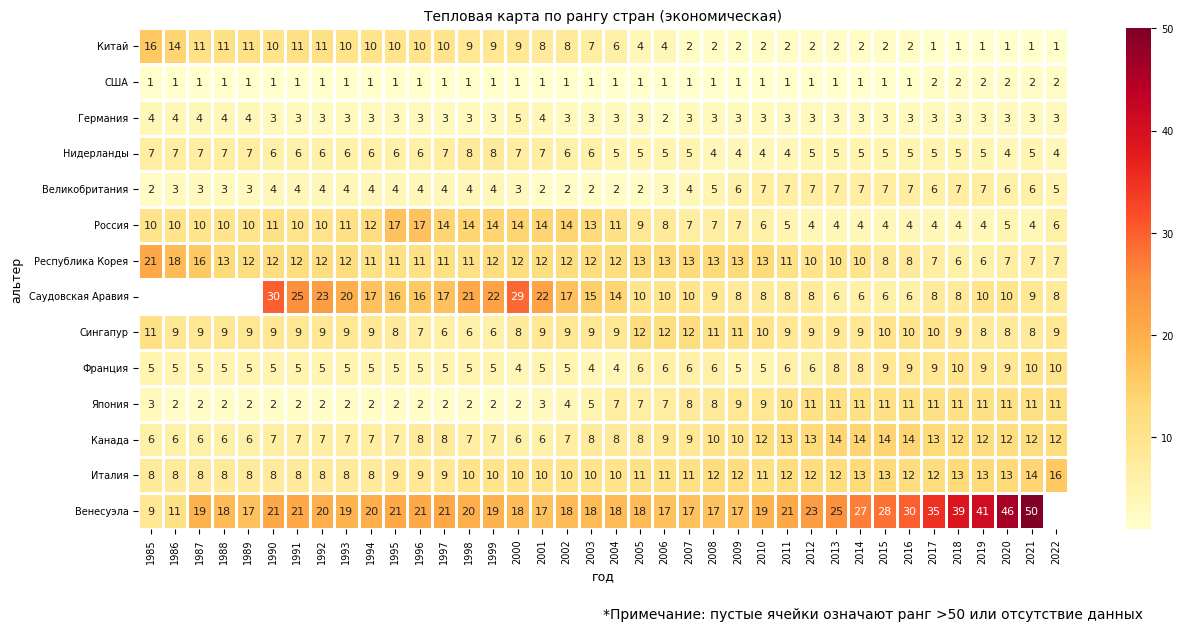

security


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61a6dc0b90>


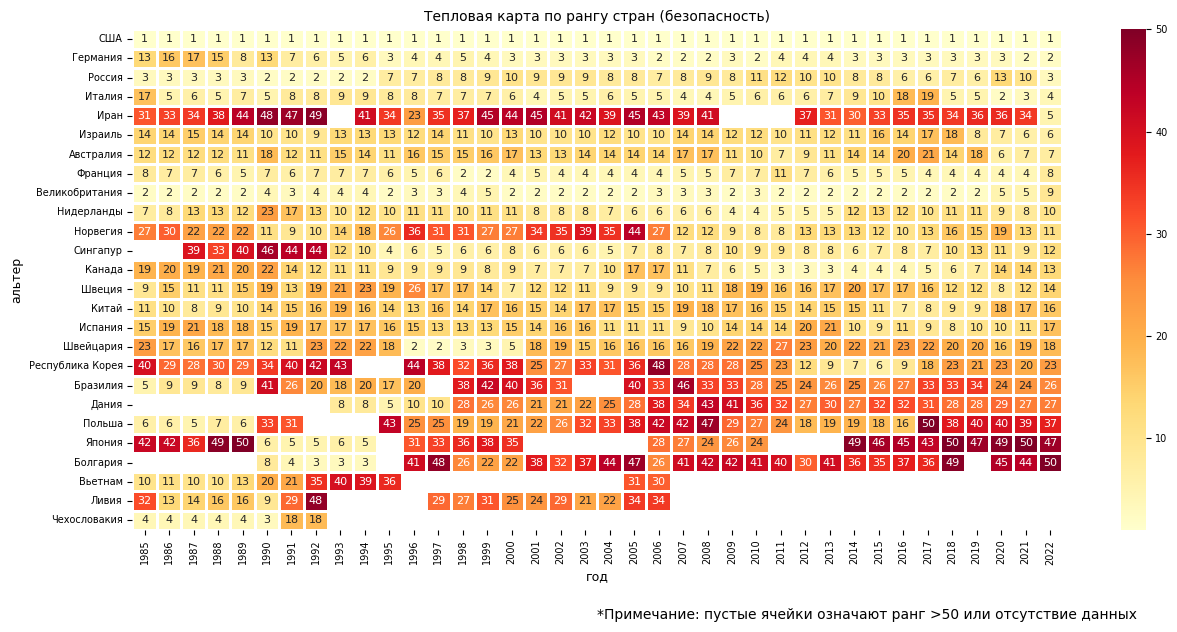

human


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61d549cbd0>


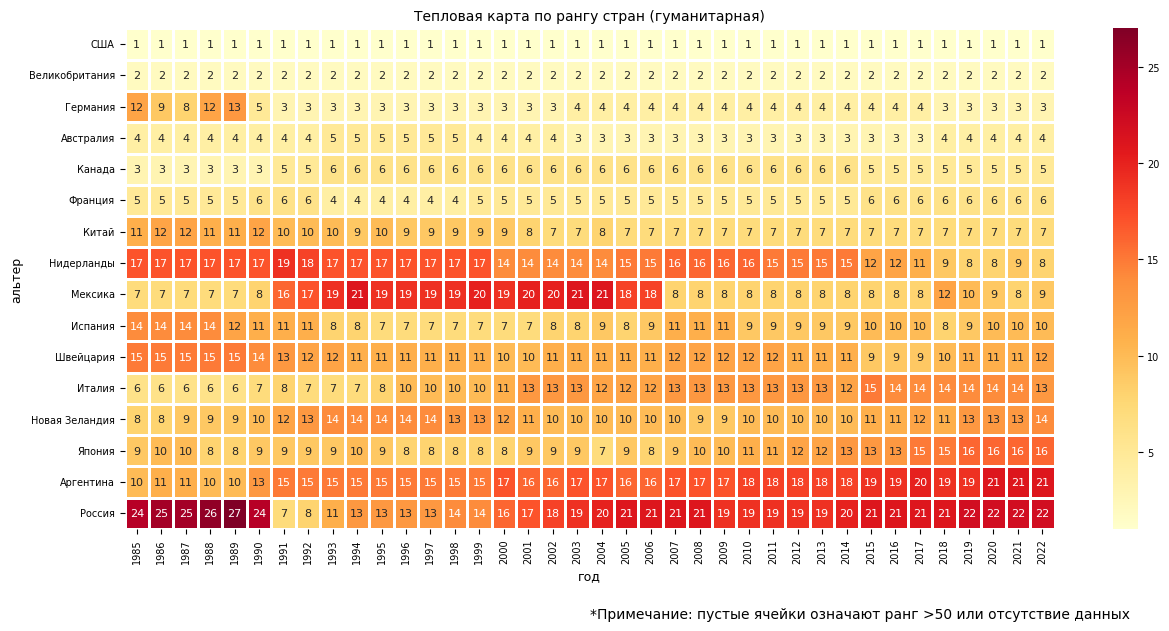

DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61d65bfb10>


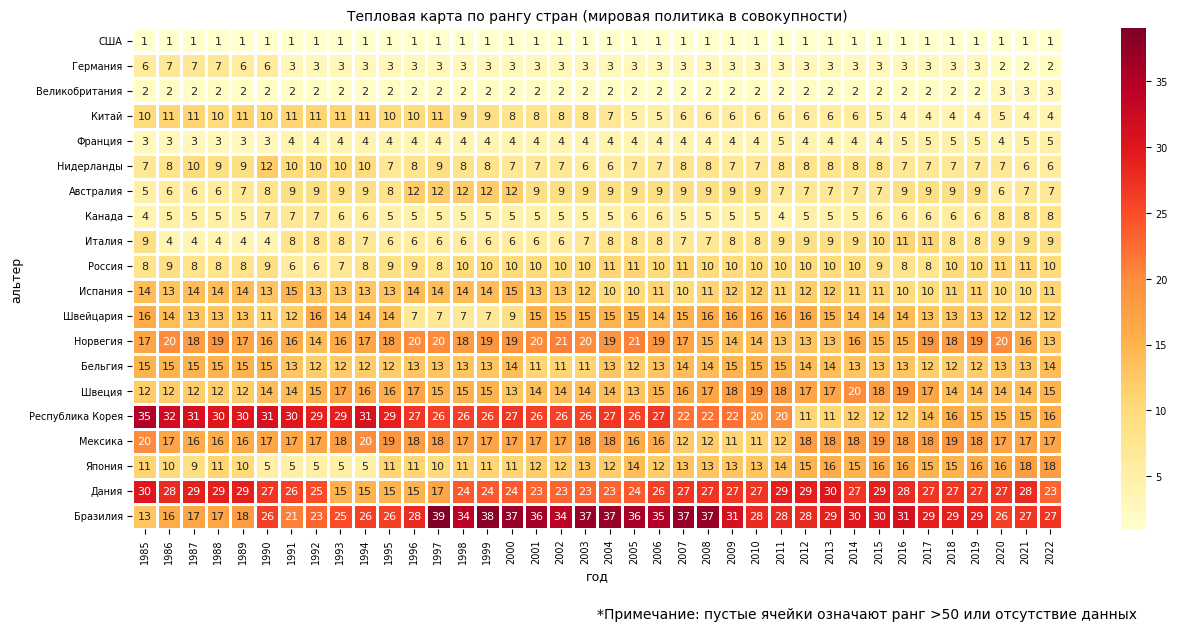

In [1368]:
for subsystem in SUBSYSTEMS:
    print(subsystem)
    visualize_sphere(analysis, sphere=subsystem, russify=True)

visualize_overall(status_combined, rankmin=15)

## Иерархичность

#### Центральность лидера

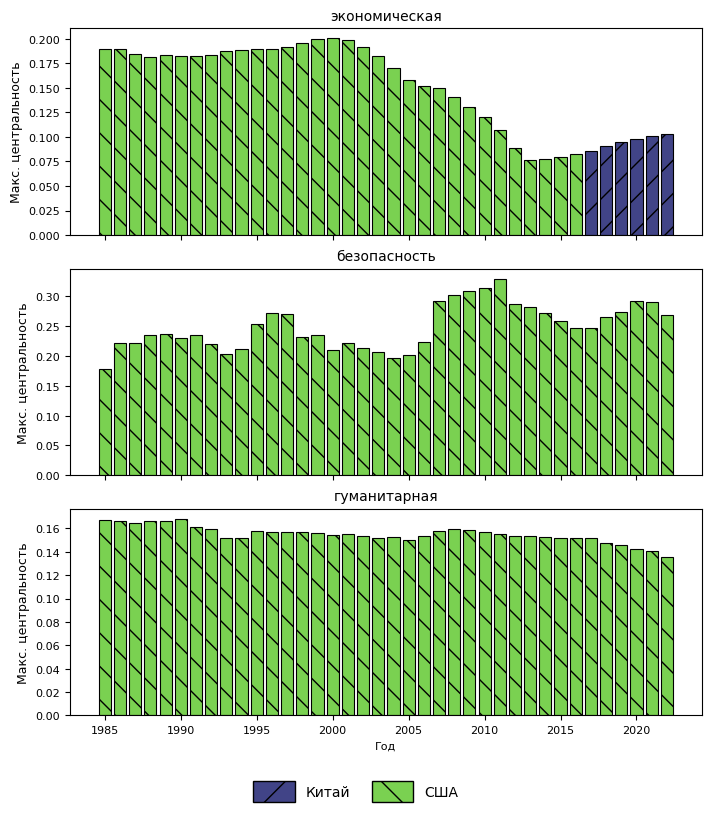

In [12]:
import matplotlib.patches as mpatches

# Шаг 1. Собираем все уникальные страны, встречающиеся хотя бы в одной подсистеме
# Шаг 1. Собираем все уникальные страны, встречающиеся хотя бы в одной подсистеме
all_countries = []
for subsystem in SUBSYSTEMS:
    df_sub = analysis[(analysis['subsystem'] == subsystem) & (analysis['rank'] <= 1)]
    for country in df_sub['ego'].unique():
        if country not in all_countries:
            all_countries.append(country)
all_countries.reverse()  # обратный порядок, как в исходном коде

# Шаг 2. Назначаем общие цвета (оттенки серого) и штриховки для всех стран
if PLOT_GREY:
    cmap = plt.get_cmap('Greys')
else:
    cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0.2, 0.8, len(all_countries)))
hatch_patterns = ['/', '\\', '-', '+', 'x', 'o', 'O', '.', '*']

color_map = {country: colors[i] for i, country in enumerate(all_countries)}
hatch_map = {country: hatch_patterns[i % len(hatch_patterns)] for i, country in enumerate(all_countries)}

# Шаг 3. Создаём фигуру с вертикальным расположением подграфиков
fig, axes = plt.subplots(
    len(SUBSYSTEMS), 1,
    figsize=(7, 2.5 * len(SUBSYSTEMS)),  # компактная высота, ширина на всю страницу
    constrained_layout=True
)

# Шаг 4. Строим графики для каждой подсистемы
for ax, subsystem in zip(axes, SUBSYSTEMS):
    df = analysis[(analysis['subsystem'] == subsystem) & (analysis['rank'] <= 1)]

    for country in df['ego'].unique():
        df_country = df[df['ego'] == country]
        label = country
        if country == 'Russian Federation':
            label = 'Russian Federation (Soviet Union)'

        ax.bar(
            df_country['year'],
            df_country['centrality'],
            label=label,
            color=color_map[country],      # общий цвет для страны
            edgecolor='black',
            linewidth=0.8,
            hatch=hatch_map[country]       # общая штриховка
        )

    # Настраиваем каждый подграфик
    ax.set_title(SUBSYSTEMS_RU[subsystem], fontsize=10)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_ylabel('Макс. центральность', fontsize=9)

    # Скрываем подписи оси X на всех графиках, кроме последнего
    if ax != axes[-1]:
        ax.tick_params(labelbottom=False)
        ax.set_xlabel('')
    else:
        ax.set_xlabel('Год', fontsize=8)

# Шаг 5. Создаём общую легенду для всей фигуры
handles = []
for country in all_countries:
    label = country
    if country == 'Russian Federation':
        label = 'Russian Federation (Soviet Union)'
    handle = mpatches.Patch(
        facecolor=color_map[country],
        edgecolor='black',
        hatch=hatch_map[country],
        label=label
    )
    handles.append(handle)

# Размещаем легенду внизу фигуры, с увеличенными элементами и достаточным отступом
fig.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),          # ниже, чем подпись оси X
    ncol=min(3, len(all_countries)),     # до трёх столбцов
    fontsize=10,                         # увеличенный шрифт
    handlelength=3.0,                    # длиннее прямоугольники
    handleheight=2.0,                    # выше прямоугольники
    columnspacing=1.5,                   # расстояние между столбцами
    handletextpad=0.8,                   # расстояние между маркером и текстом
    frameon=False
)

# Шаг 6. Сохраняем с автоматической обрезкой полей и дополнительным запасом
plt.savefig(
    f'../output/leader_centrality_all{"_grey" if PLOT_GREY else ""}.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.1
)
plt.show()

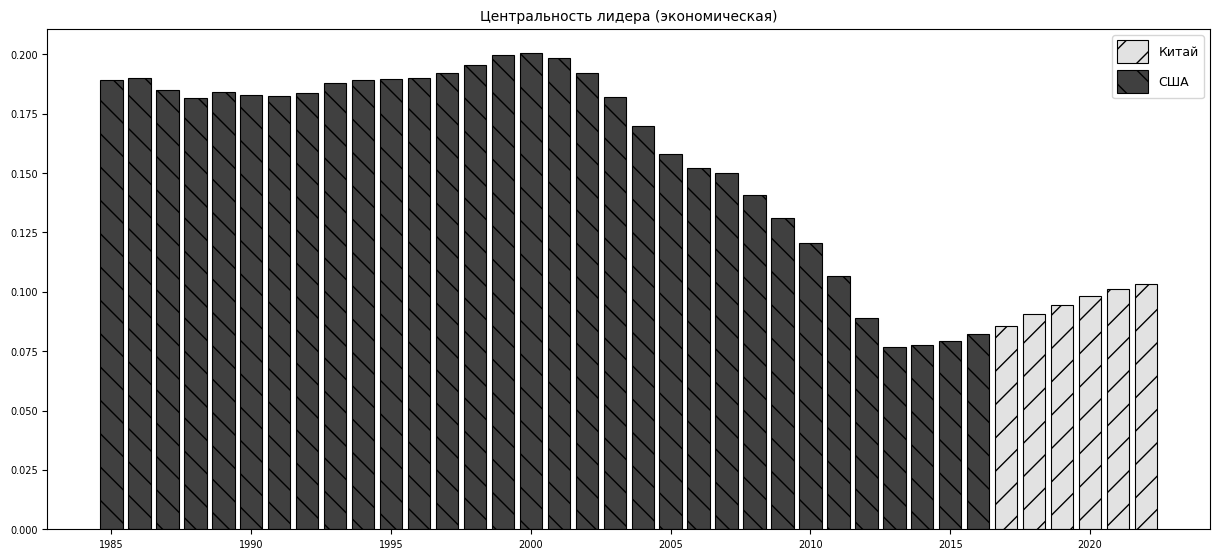

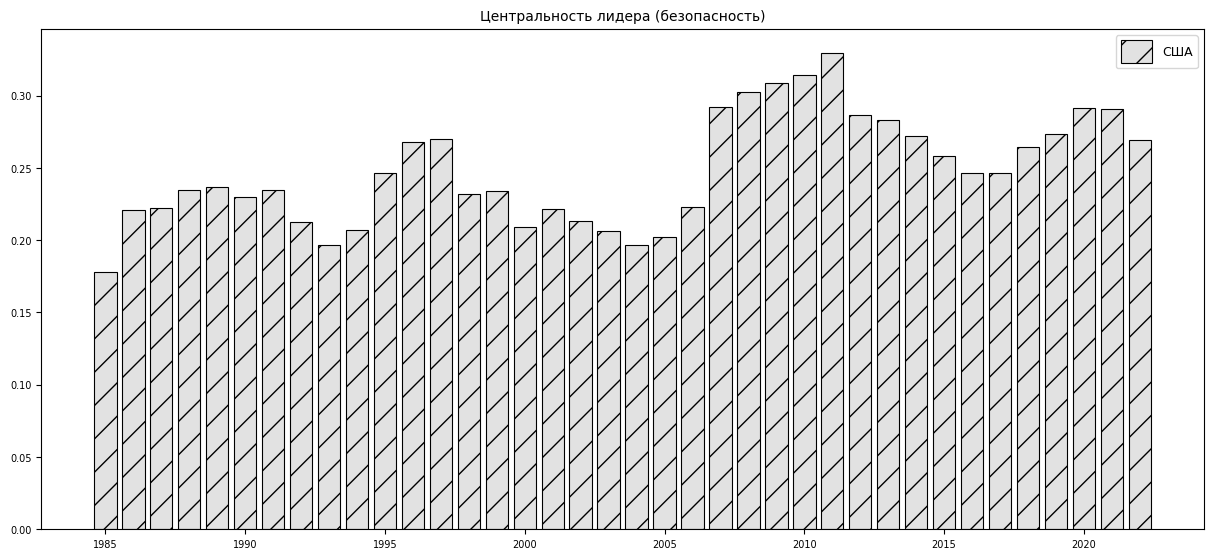

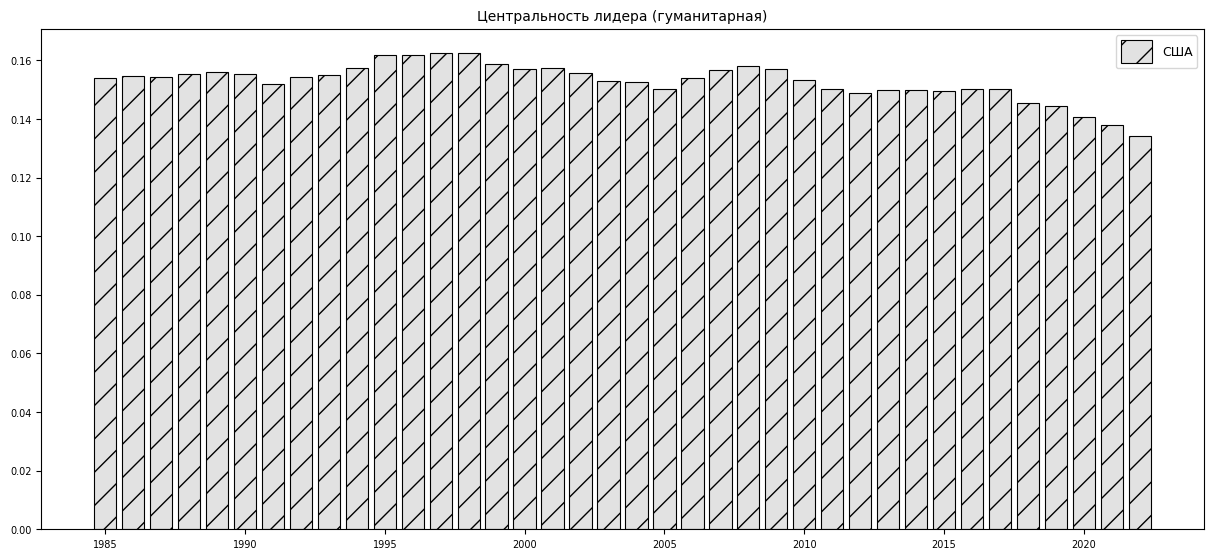

In [1262]:
for subsystem in SUBSYSTEMS:
    df = analysis[analysis['subsystem'] == subsystem]
    df = df[df['rank'] <= 1]
    
    plt.figure(figsize=(15, 6.5))
    countrynames = list(df['ego'].unique())
    countrynames.reverse()
    
    # Оттенки серого
    cmap = plt.get_cmap('Greys')
    colors = cmap(np.linspace(0.2, 0.8, len(countrynames)))
    
    # Список доступных штриховок (можно добавить ещё)
    hatch_patterns = ['/', '\\', '|', '-', '+', 'x', 'o', 'O', '.', '*']
    
    for i, countryname in enumerate(countrynames):
        df_country = df[df['ego'] == countryname]
        label = countryname
        if countryname == 'Russian Federation':
            label = 'Russian Federation (Soviet Union)'
        
        hatch = hatch_patterns[i % len(hatch_patterns)]
        
        plt.bar(df_country['year'], df_country['centrality'],
                label=label,
                color=colors[i],
                edgecolor='black',     # чёткая граница
                linewidth=0.8,         # небольшая рамка
                hatch=hatch)
    
    # Легенда с увеличенными прямоугольниками и читаемым размером шрифта
    plt.legend(handlelength=2.5, handleheight=2.5, fontsize=9)
    plt.title(f'Центральность лидера ({SUBSYSTEMS_RU[subsystem]})')
    plt.savefig(f'../output/{subsystem}_leader_centrality.png',
                dpi=300, bbox_inches='tight')
    plt.show()


#### Коэффициент демократичности

In [1204]:
# trophic coherence
## Moutsinas, G., Shuaib, C., Guo, W., & Jarvis, S. (2019). Graph hierarchy and spread of infections. arXiv preprint arXiv:1908.04358 
## https://www.nature.com/articles/s41598-021-93161-4
# https://github.com/shuaib7860/GraphHierarchy

In [18]:
# import GraphHierarchy as gh -- broken, adding a local fork instaed
from analysis import gh_fixed

In [19]:
def detect_hierarchy(subsystems):
    hierarchy_metrics = {}
    for subsystem in SUBSYSTEMS:
        hierarchy_metrics_sphere = {}
        for y in range (YEAR_START, YEAR_END+1):
            
            nodelist = list(subsystems[subsystem]['networks'][y].nodes())  # либо sorted(G.nodes()) или ваша предпочтительная упорядоченность
            # 2) Плотная numpy-матрица смежности для взвешенной матрицы по атрибуту 'weight':
            A_weighted = subsystems[subsystem]['networks'][y]#nx.to_numpy_array(subsystems[subsystem]['networks'][y], nodelist=nodelist, dtype=float, weight='weight')
            #print(A_weighted)
            #hierarchical_levels = gh.forward_hierarchical_levels(A_weighted, weight='value') #a weighted adjacency matrix, an N$\times$N dimensional array with the weights representing the forward hierarchical differences.
            #hierarchical_incoherence = gh.forward_hierarchical_incoherence(A_weighted, weight='value') # The function forward hierarchical incoherence returns the forward hierarchical differences sparse array and the associated mean and standard deviation of this distribution:
            #democracy_coef = gh.forward_democracy_coefficient(A_weighted, weight='value')
            #influence_centrality = gh.forward_influence_centrality(A_weighted, weight='value')

            hierarchical_levels = gh_fixed.backward_hierarchical_levels(A_weighted, weight='weight') #a weighted adjacency matrix, an N$\times$N dimensional array with the weights representing the forward hierarchical differences.
            hierarchical_incoherence = gh_fixed.backward_hierarchical_incoherence(A_weighted, weight='weight') # The function forward hierarchical incoherence returns the forward hierarchical differences sparse array and the associated mean and standard deviation of this distribution:
            democracy_coef = gh_fixed.backward_democracy_coefficient(A_weighted, weight='weight')
            influence_centrality = gh_fixed.backward_influence_centrality(A_weighted, weight='weight')
            influence_centrality = pd.DataFrame(list(zip(nodelist, influence_centrality)), columns=['ego','hierarchy_centrality']).sort_values('hierarchy_centrality')  # очень странная иерархия
            hierarchical_levels = pd.DataFrame(list(zip(nodelist, hierarchical_levels)), columns=['ego','hierarchical_levels']).sort_values('hierarchical_levels')  # очень странная иерархия
            hierarchy_metrics_sphere[y] = {'levels':hierarchical_levels,
                                    'incoherence':hierarchical_incoherence,
                                    'democracy_coef':democracy_coef,
                                    'influence_centrality':influence_centrality
                                   }
        hierarchy_metrics[subsystem]=hierarchy_metrics_sphere
        # Что-то не так с 2011 годом, надо разобраться
    return hierarchy_metrics

In [20]:
hierarchy_metrics = detect_hierarchy(subsystems)

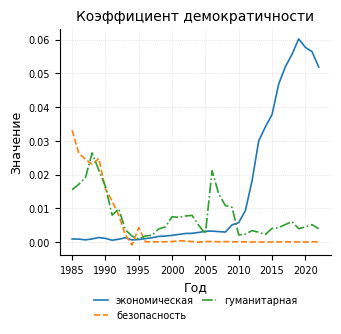

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))  # чуть выше, чтобы вместить легенду

for i, subsystem in enumerate(SUBSYSTEMS):
    # Извлекаем ряд данных
    series = pd.DataFrame.from_dict(hierarchy_metrics[subsystem]).loc['democracy_coef']
    
    # Выбираем стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    if PLOT_GREY:
        ax.plot(
            series.index, series.values,
            linestyle=style,
            color='black',
            label=SUBSYSTEMS_RU.get(subsystem, subsystem)
        )
    else:
        ax.plot(
            series.index, series.values,
            linestyle=style,
            label=SUBSYSTEMS_RU.get(subsystem, subsystem)
        )

# Оформление осей
ax.set_title('Коэффициент демократичности')
ax.set_xlabel('Год')
ax.set_ylabel('Значение')
ax.grid(True, linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/democracy_coef{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()


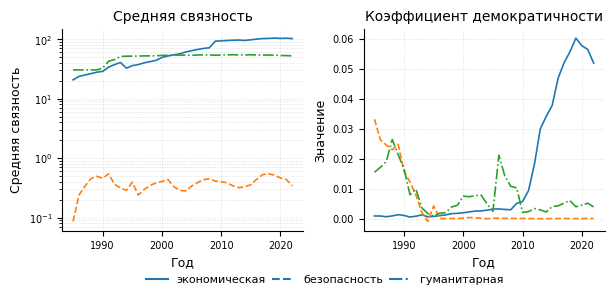

In [22]:
from matplotlib.lines import Line2D

# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Стили линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Список сфер (подсистем)
spheres = SUBSYSTEMS  # например ['security', 'economy', ...]

if PLOT_GREY:
    color = 'black'
else:
    color = None
    
# Создаём фигуру с двумя подграфиками в ряд
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.2))

# --- Левый график: средняя связность (логарифмическая шкала) ---
for i, sphere in enumerate(spheres):
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere].sort_values('year')
    style = line_styles[i % len(line_styles)]
    ax1.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color=color
    )

ax1.set_yscale('log')
ax1.set_title('Средняя связность')
ax1.set_xlabel('Год')
ax1.set_ylabel('Средняя связность')
ax1.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- Правый график: коэффициент демократичности ---
for i, sphere in enumerate(spheres):
    series = pd.DataFrame.from_dict(hierarchy_metrics[sphere]).loc['democracy_coef']
    style = line_styles[i % len(line_styles)]
    ax2.plot(
        series.index, series.values,
        linestyle=style,
        color=color
    )

ax2.set_title('Коэффициент демократичности')
ax2.set_xlabel('Год')
ax2.set_ylabel('Значение')
ax2.grid(True, linestyle=':', linewidth=0.5, color='lightgray')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- Общая легенда (под графиками) ---
handles = []
for i, sphere in enumerate(spheres):
    style = line_styles[i % len(line_styles)]
    label = SUBSYSTEMS_RU.get(sphere, sphere) if 'SUBSYSTEMS_RU' in globals() else sphere
    # ВАЖНО: добавляем label в Line2D
    handle = Line2D([0], [0], color=color, linestyle=style, linewidth=1.5, label=label)
    handles.append(handle)

# Размещаем легенду под графиками
fig.legend(
    handles=handles,
    loc='lower center',            # привязка к нижнему центру
    bbox_to_anchor=(0.5, 0.05),   # сдвиг вниз, но не слишком большой
    ncol=min(3, len(spheres)),
    fontsize=8,
    handlelength=2.0,
    columnspacing=0.54,
    frameon=False
)

# Ручная настройка полей: уменьшаем зазор между графиками, оставляем место для легенды
plt.subplots_adjust(wspace=0.25, bottom=0.25)  # bottom увеличен для гарантии видимости легенды

# Сохранение с обрезкой полей
plt.savefig(
    f'../output/combined_horizontal{"_grey" if PLOT_GREY else ""}.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.2
)
plt.show()

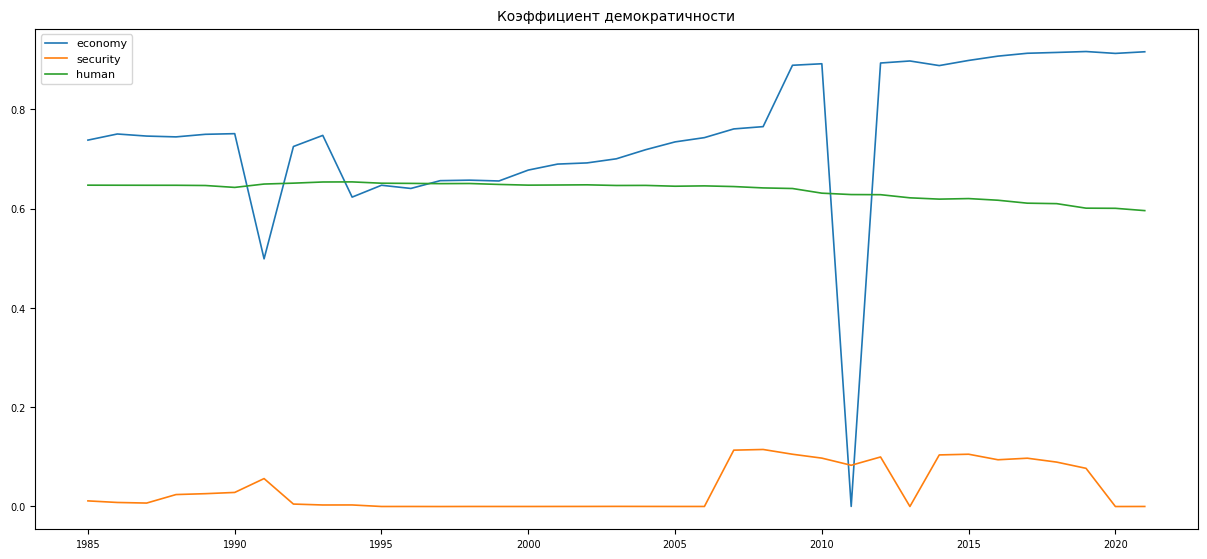

In [1379]:
plt.figure(figsize=(15, 6.5))
for subsystem in SUBSYSTEMS:
    plt.plot(pd.DataFrame.from_dict(hierarchy_metrics[subsystem]).loc['democracy_coef'], label=subsystem)
plt.legend()
plt.title('Коэффициент демократичности')
plt.savefig(f'../output/democracy_coef.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 1 - проверяем, действительно ли этапы структурной перестройки выделены корректно
# 2 - анализ

#### Core-periphery analysis

In [1382]:
# https://github.com/skojaku/core-periphery-detection
import cpnet

ModuleNotFoundError: No module named 'cpnet'

In [1380]:
def detect_core_periphery(subsystems):
    core_periphery_metrics = {}
    #algorithm = cpnet.KM_config()  # плохой алгоритм, подобрать учитывающий веса
    algorithm = cpnet.Rombach()
    for subsystem in SUBSYSTEMS:
        core_periphery_metrics_sphere = {}
        for y in range (YEAR_START, YEAR_END):
            algorithm.detect(subsystems['security']['networks'][y])
            core_periphery_metrics_sphere[y] = {
                'pair_ids':algorithm.get_pair_id(),
                'coreness':algorithm.get_coreness()
            }
        core_periphery_metrics[subsystem]=core_periphery_metrics_sphere
        # Что-то не так с 2011 годом, надо разобраться
    return core_periphery_metrics

In [1381]:
core_periphery = detect_core_periphery(subsystems)
# странные результаты

NameError: name 'cpnet' is not defined

In [762]:
correls = []
for c_a, c_b in list(product(analysis['ego'].unique(), analysis['ego'].unique())):
    print(c_a, c_b)
    if c_a == c_b: continue
    try:
        r = pearsonr(analysis[(analysis['ego']==c_a)&(analysis['subsystem']=='security')]['status'], analysis[(analysis['ego']==c_b)&(analysis['subsystem']=='security')]['status'])
    except Exception as E:
        print(E)
        r = [None, None]
    correls += [c_a, c_b, r[0], r[1]],

Kuwait Kuwait
Kuwait El Salvador
Kuwait Dominican Republic
Kuwait Sudan
Kuwait Somalia
Kuwait Papua New Guinea
Kuwait Sri Lanka
Kuwait Democratic Republic of the Congo
Kuwait Malawi
Kuwait Mauritania
Kuwait Hungary
Kuwait Bangladesh
Kuwait Romania
Kuwait Peru
Kuwait Kenya
Kuwait Haiti
Kuwait Argentina
Kuwait Saint Vincent and the Grenadines
Kuwait Venezuela (Bolivarian Republic of)
Kuwait Trinidad and Tobago
Kuwait Togo
Kuwait Chad
Kuwait Burundi
Kuwait Malaysia
Kuwait Côte d'Ivoire
Kuwait Tunisia
Kuwait United Arab Emirates
Kuwait Niger
Kuwait Lebanon
Kuwait Mongolia
Kuwait Djibouti
Kuwait Paraguay
Kuwait Comoros
Kuwait Germany
Kuwait Vanuatu
Kuwait Zambia
Kuwait Panama
Kuwait Malta
Kuwait Samoa
Kuwait Grenada
Kuwait Solomon Islands
Kuwait Rwanda
Kuwait Barbados
Kuwait Qatar
Kuwait Guatemala
Kuwait Equatorial Guinea
Kuwait Botswana
Kuwait Brunei Darussalam
Kuwait Costa Rica
Kuwait Bulgaria
Kuwait Mexico
Kuwait State of Palestine
Kuwait Liberia
Kuwait Cameroon
Kuwait Suriname
Kuwait Cy

In [774]:
res_df = pd.DataFrame(correls).dropna()
res_df.columns = ['ego', 'alter', 'r', 'p']
res_df.sort_values('r', inplace=True)
res_df.to_excel('../output/correlations_100825.xlsx')

In [773]:
res_df#[(res_df['p']<0.99)&res_df['r']<0.999].head()

,ego,alter,r,p
30955,United States,German Democratic Republic,-0.960732,1.239943e-21
28432,German Democratic Republic,United States,-0.960732,1.239943e-21
26677,Lao People's Democratic Republic,United States,-0.959444,2.193279e-21
30946,United States,Lao People's Democratic Republic,-0.959444,2.193279e-21
30577,South Africa,United States,-0.944696,5.164967e-19
...,...,...,...,...
7460,Samoa,State of Palestine,1.000000,0.000000e+00
7453,Samoa,Guatemala,1.000000,0.000000e+00
7451,Samoa,Barbados,1.000000,0.000000e+00
7482,Samoa,Jamaica,1.000000,0.000000e+00
